In [ ]:
+import crflux.models as pm
import matplotlib.pyplot as plt

from MCEq.core import MCEqRun

In [2]:
mceq_run = MCEqRun(
interaction_model='SIBYLL23D',
primary_model=(pm.HillasGaisser2012, "H3a"),
theta_deg=0.
)


MCEqRun::set_interaction_model(): SIBYLL23D
ParticleManager::_init_default_tracking(): Initializing default tracking categories (pi, K, mu)
MatrixBuilder::_fill_matrices(): No interactions by D_s- ((-431, 0)).
MatrixBuilder::_fill_matrices(): No interactions by D_s+ ((431, 0)).
MCEqRun::set_density_model(): Setting density profile to CORSIKA ('BK_USStd', None)
MCEqRun::set_primary_model(): Primary model set to Hillas-Gaisser (H3a)


In [3]:
mup_dict, numu_dict, nue_dict, nutau_dict = {}, {}, {}, {}
for atm_tup in [(('CORSIKA', ('PL_SouthPole', 'January')), 'red'),
                (('CORSIKA', ('PL_SouthPole', 'August')), 'lightblue'),
                (('MSIS00', ('SouthPole', 'January')), 'darkred'),
                (('MSIS00', ('SouthPole', 'August')), 'blue'),
                (('CORSIKA', ('BK_USStd', None)), 'black')]:


    mceq_run.set_density_model(atm_tup[0])
    for theta in [0., 90.]:

        mceq_run.set_theta_deg(theta)
        mceq_run.solve()

        mag = 3

        mup_dict[(theta, atm_tup)] = mceq_run.get_solution('total_mu+', mag) + \
                               mceq_run.get_solution('total_mu-', mag)

        numu_dict[(theta, atm_tup)] = mceq_run.get_solution('total_numu', mag) + \
                                mceq_run.get_solution('total_antinumu', mag)

        nue_dict[(theta, atm_tup)] = mceq_run.get_solution('total_nue', mag) + \
                               mceq_run.get_solution('total_antinue', mag)
        nutau_dict[(theta, atm_tup)] = (mceq_run.get_solution('total_nutau', mag) +
                                mceq_run.get_solution('total_antinutau', mag)
)
mup_dict.keys()
color_spectrum = ['b', 'r', 'g', 'orange', 'cyan', 'violet',
                  'brown', 'pink', 'yellow', 'lightblue']
titles = {('CORSIKA', ('PL_SouthPole', 'January')): 'CKA SP/Jan',
          ('CORSIKA', ('PL_SouthPole', 'August')): 'CKA SP/Aug',
          ('MSIS00', ('SouthPole', 'January')): 'MSIS00 SP/Jan',
          ('MSIS00', ('SouthPole', 'August')): 'MSIS00 SP/Aug',
          ('CORSIKA', ('BK_USStd', None)):'USStd'}



MCEqRun::set_density_model(): Setting density profile to CORSIKA ('PL_SouthPole', 'January')
MCEqRun::set_density_model(): Setting density profile to CORSIKA ('PL_SouthPole', 'August')
MCEqRun::set_density_model(): Setting density profile to MSIS00 ('SouthPole', 'January')
MCEqRun::set_density_model(): Setting density profile to MSIS00 ('SouthPole', 'August')
MCEqRun::set_density_model(): Setting density profile to CORSIKA ('BK_USStd', None)


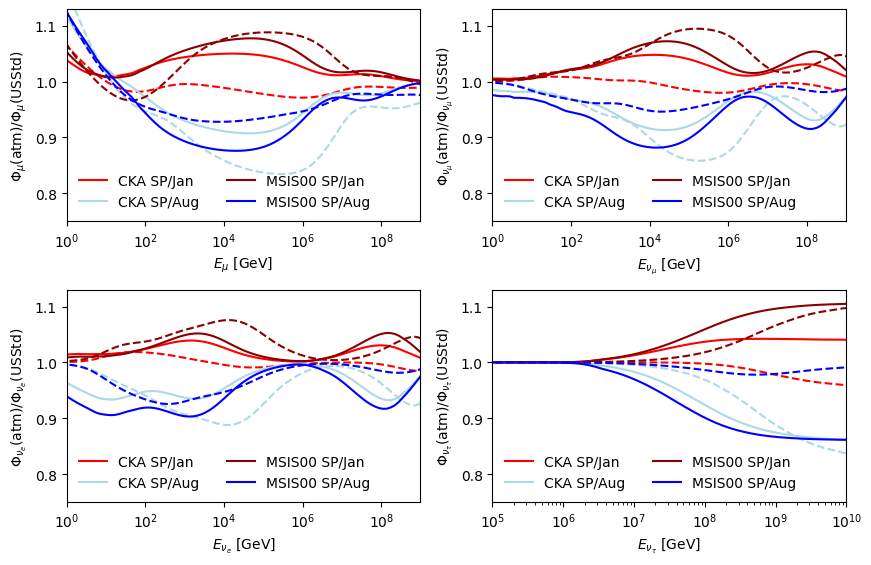

In [4]:
fig = plt.figure(figsize=(9, 6))

fig.set_tight_layout(dict(rect=[0.01, 0.01, 0.99, 0.97]))
e_grid = mceq_run.e_grid
# Define base line
compare_to = (('CORSIKA', ('BK_USStd', None)), 'black')

for theta, atm_tup in mup_dict:
    atm_config, atm_col = atm_tup

    if atm_config[1][0].startswith('BK'):
        continue

    mup_comp = mup_dict[(theta, compare_to)]
    numu_comp = numu_dict[(theta, compare_to)]
    nue_comp = nue_dict[(theta, compare_to)]
    nutau_comp = nutau_dict[(theta, compare_to)]

    ls = '--'
    atm_title = '_nolabel_'
    if theta < 90.:
        ls='-'
        atm_title = titles[atm_config]


    plt.subplot(221)
    plt.plot(e_grid, mup_dict[(theta, atm_tup)] / mup_comp, ls=ls, lw=1.5,
             color=atm_col, label=atm_title)
    plt.semilogx()
    plt.xlabel(r"$E_{\mu}$ [GeV]")
    plt.ylim([0.75, 1.1])

    plt.subplot(222)
    plt.plot(e_grid, numu_dict[(theta, atm_tup)] / numu_comp, ls=ls,  lw=1.5,
             color=atm_col, label=atm_title)
    plt.semilogx()
    plt.xlabel(r"$E_{\nu}$ [GeV]")


    plt.subplot(223)
    plt.plot(e_grid, nue_dict[(theta, atm_tup)] / nue_comp, ls=ls,  lw=1.5,
             color=atm_col, label=atm_title)
    plt.semilogx()
    plt.xlabel(r"$E_{\nu_e}$ [GeV]")

    plt.subplot(224)
    plt.plot(e_grid, nutau_dict[(theta, atm_tup)] / nutau_comp, ls=ls, lw=1.5,
            color=atm_col, label=atm_title)
    plt.semilogx()
    plt.xlabel(r"$E_{\nu_\tau}$ [GeV]")

plt.subplot(221)
plt.xlabel(r"$E_{\mu}$ [GeV]")
plt.ylabel(r"$\Phi_{\mu}($atm$)/\Phi_{\mu}($USStd)")
plt.xlim([1,1e9])
plt.ylim([0.75, 1.13])
plt.legend(loc='lower left', ncol=2, frameon=False, fontsize=10)

plt.subplot(222)
plt.xlabel(r"$E_{\nu_\mu}$ [GeV]")
plt.ylabel(r"$\Phi_{\nu_\mu}($atm$)/\Phi_{\nu_\mu}($USStd)")
plt.xlim([1,1e9])
plt.ylim([0.75, 1.13])
plt.legend(loc='lower left', ncol=2, frameon=False, fontsize=10)

plt.subplot(223)
plt.xlabel(r"$E_{\nu_e}$ [GeV]")
plt.ylabel(r"$\Phi_{\nu_e}($atm$)/\Phi_{\nu_e}($USStd)")
plt.xlim([1,1e9])
plt.ylim([0.75, 1.13])
plt.legend(loc='lower left', ncol=2, frameon=False, fontsize=10)

plt.subplot(224)
plt.xlabel(r"$E_{\nu_\tau}$ [GeV]")
plt.ylabel(r"$\Phi_{\nu_\tau}($atm$)/\Phi_{\nu_\tau}($USStd)")
plt.xlim([1e5, 1e10])
plt.ylim([0.75, 1.13])
plt.legend(loc='lower left', ncol=2, frameon=False, fontsize=10)

plt.show()
